## Preliminaries

**Pixel FLipping** with **Monte-Carlo Dropout** for whole classes in the test set.

In [1]:
!pwd
#import os
#os.chdir('C:\\Users\\Teo\\Documents\\Projects') # equivalent to /teo on server

import sys
sys.path.append('./tf-explain/')
sys.path.append('./Quantus/Quantus/')
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import time
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.utils import metafile_readers as mr # an extra prefix beexplainable. may be needed
from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from wingbeats import modelling as wm # for building simple classifiers
from wingbeats import xai as wx

from tf_explain.core.vanilla_gradients import VanillaGradients
from tf_explain.core.gradients_inputs import GradientsInputs
from tf_explain.core.integrated_gradients import IntegratedGradients

In [3]:
use_mini_dataset   = True
compress_B_lucorum = True
bees_subfolder = '22_species/' if compress_B_lucorum else '25_species/'

dataset_folder = 'Bees_Christian/' if use_mini_dataset else 'Bees/'
metafolder = './beexplainable/metafiles/'

BEES_PATH = '../data/data_lstudio/' + dataset_folder
IMAGES_PATH = metafolder + dataset_folder + 'images.txt'
MASKS_PATH = metafolder + dataset_folder + 'masks.txt'
IMAGES_LABELS_PATH = metafolder + dataset_folder + bees_subfolder + 'image_class_labels.txt'
CLASSES_PATH = metafolder + dataset_folder + bees_subfolder + 'classes.txt'

W_H_PATH = metafolder + dataset_folder + 'widths_heights.txt'
BBOX_PATH = metafolder + dataset_folder + 'bounding_boxes.txt'
PART_CONTOURS = metafolder + dataset_folder + 'part_contours.npy'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/pf_mcd_testset/'

## Load images

In [4]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids = list( img_dict.keys() )
y_true   = list( img_label_dict.values() )
y_true   = np.asarray(y_true, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0

# Read class names
cls_dict = mr.metafile_to_dict(CLASSES_PATH)
classes = list( cls_dict.values() )

In [5]:
batch_size = len(file_ids)
img_height = img_width = 224
crop_to_bbox = False # whether to crop image to bbox
overlay_mask = False # whether to segment object and hide background

In [6]:
# Add extension to path if extra input transformation is enabled
input_form = 'raw'
if crop_to_bbox and not overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_bbox/'
    input_form = 'bbox'
elif not crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked/Whole/'
    input_form = 'mask'
elif crop_to_bbox and overlay_mask:
    BEES_PATH = BEES_PATH[:-1] + '_masked_bbox/'
    input_form = 'mask_bbox'
print(BEES_PATH)

../data/data_lstudio/Bees_Christian/


In [7]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids,
                                                                           list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BEES_PATH),
                                          label)

In [8]:
# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids, y_true, parse_image_lab)
test_set = test_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images (first item in the tuples, second is the mask)
normalization_layer = Rescaling(1./255)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

In [9]:
for image_batch, labels_batch in test_set.take(1):
    print(image_batch[0].shape)
    print(labels_batch[0])

(224, 224, 3)
tf.Tensor(0, shape=(), dtype=uint8)


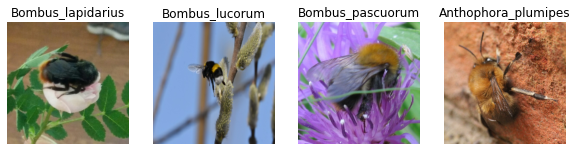

In [10]:
plt.figure(figsize = (10, 10))
num_cols = min(4, batch_size)
with tf.device('/CPU:0'):
    for images, labels in test_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(cls_dict[str(labels[i].numpy()+1)])
            plt.axis("off")
plt.show()

## XAI

### Pixel Flipping + MCDropout for whole classes in test set

In [11]:
# Define initial parameters
in_shape = (img_width, img_height, 3)
drop_rate, lr, reg = 0.5, 1e-4, 1e-4

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_accuracy')]

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
dataset_type = 'all' # model was trained on whole dataset and is now tested on mini dataset
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_raw' # model was trained on raw whole dataset
weights_file = MODELS_PATH + dataset_type + '/' + bees_subfolder + model_name + '/' + model_name + '.h5' # path to load weights from
print('Model loaded from ' + weights_file)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

Model loaded from ./beexplainable/models/all/22_species/ResNet50_iNat_raw/ResNet50_iNat_raw.h5


In [12]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(weights_file)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

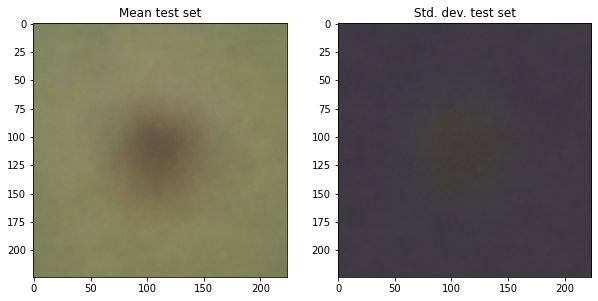

In [13]:
# Compute mean img and std img for whole test set
for img_batch, lab_batch in test_set.take(1):
    mean_img = tf.math.reduce_mean(img_batch, axis = 0)
    std_img  = tf.math.reduce_std(img_batch,  axis = 0)

plt.figure(figsize = (10, 5))
plt.subplot(121)
plt.imshow(mean_img)
plt.title('Mean test set')

plt.subplot(122)
plt.imshow(std_img)
plt.title('Std. dev. test set')
plt.show()

In [14]:
# Flipping parameters
percent_to_flip = 0.25
percent_step = 0.005
percents = int(percent_to_flip*100)
num_scores = int(percent_to_flip / percent_step) + 1

# XAI methods from tf-explain
explainers = [VanillaGradients(), GradientsInputs(), IntegratedGradients()]
expl_names = ['Gradient', 'InputXGradient', 'IntegratedGradients']

# MCD-Quantiles parameters
num_infer = 100
nbins = 25
q = [0.25, 0.5, 0.75]
grad_leg  = ['Grad ' + str(quant) for quant in q] # For plot legends
gradInp_leg = ['G-Inp ' + str(quant) for quant in q]
intGrad_leg = ['Int-G ' + str(quant) for quant in q]

In [15]:
# Pick all or a few samples of one species from test set
target_ind = 5 # starts at 0
ex_specs, counts, max_specs = [], 0, 30
for img_batch, lab_batch in test_set:
    for img, lab in zip(img_batch, lab_batch):
        if lab == target_ind:
            # Change format for Gradient Tape and append signal
            ex_specs.append(img)
            counts += 1
            if counts == max_specs: break

print(str(len(ex_specs)) + ' samples ' + classes[target_ind])

30 samples Osmia_bicornis


In [16]:
# Apply pixel flipping for the whole species (or batch) in the test set
q_pred_scores_target = np.zeros((len(explainers)*len(q)+1, num_scores)) # 3 quantiles for each xai meth. and one random flipping
model_no_soft = tf.keras.models.Model(model.input, model.layers[-2].output) # for PF, the model preds. should not be normalized
model.layers[1].mcdrop = True
model_no_soft.layers[1].mcdrop = False
counts = 0

start_time = time.time()
for ex_spec in ex_specs:

    # MCDrop Predictions
    for ind_exp, e in enumerate(explainers):
        n_maps = []
        for _ in range(num_infer):
            hm = e.explain((np.array([ex_spec]), None), model, target_ind, norm = "min_max")
            # tf-explain removes softmax itself
            n_maps.append(hm)

        # Compute distribution of MCD heatmaps and add q-maps to dict.
        q_maps = wx.quantile_maps(n_maps, q, nbins) # len_q x img_height x img_width

        for i in range(len(q_maps)):
            pred_scores_target, _, _ = wx.flip_pixels(model_no_soft, tf.expand_dims(ex_spec, axis=0), mean_img, std_img,
                                                      percent_to_flip, percent_step, q_maps[i])
            # Add scores of current image to corresponding quantile
            q_pred_scores_target[i+ind_exp*len(q_maps)] += np.asarray(pred_scores_target)[:, target_ind]

    # One extra computation for random flipping
    pred_scores_target, _, _ = wx.flip_pixels(model_no_soft, tf.expand_dims(ex_spec, axis=0), mean_img, std_img,
                                              percent_to_flip, percent_step, None)
    # Add scores of current image to corresponding quantile
    q_pred_scores_target[-1] += np.asarray(pred_scores_target)[:, target_ind]

    counts += 1
    if counts%5==0: print(f"Finished {counts} images!")

# Divide by number of images to get mean
q_pred_scores_target /= len(ex_specs)
print("--- %s seconds ---" % (time.time() - start_time))

Finished 5 images!
Finished 10 images!
Finished 15 images!
Finished 20 images!
Finished 25 images!
Finished 30 images!
--- 2441.8185799121857 seconds ---


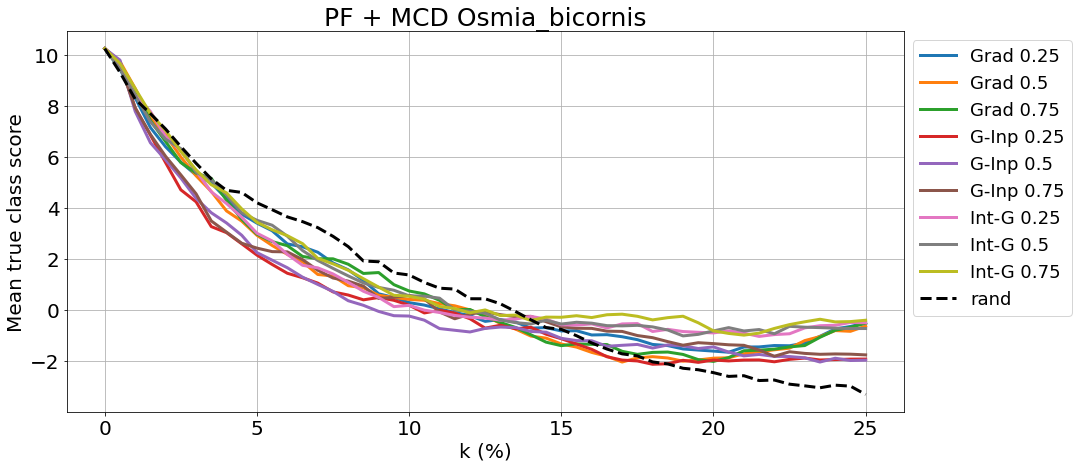

In [17]:
title_size, ticks_size = 25, 20
fig = plt.figure(figsize=(15, 7))
for i in range(len(q_pred_scores_target)):
    plt.plot(np.linspace(0, percents, num_scores), q_pred_scores_target[i],
             'k--' if i == len(q_pred_scores_target)-1 else '-', lw=3)
plt.title('PF + MCD ' + classes[target_ind], fontsize = title_size)
plt.xticks(np.linspace(0, percents, percents//5+1), fontsize = ticks_size)
plt.yticks(fontsize = ticks_size)
plt.xlabel('k (%)', fontsize = ticks_size)
plt.ylabel('Mean true class score', fontsize = ticks_size)
plt.legend(grad_leg + gradInp_leg + intGrad_leg + ['rand'], bbox_to_anchor=(1.0, 1.0), loc='upper left', fontsize = ticks_size-2)
plt.grid()
fig.savefig(FIGURES_PATH + classes[target_ind] + '_pfmcd_curves.png', bbox_inches = 'tight')
plt.show()